In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression
import time
import matplotlib.pyplot as plt
import seaborn as sns

### First create one point hpi dataframe

In [2]:
def build_features_from_hpi_dataframe(df_hpi, year_column='Year', min_year=2015):
    """
    Aplica transformaciones estadísticas a cada columna (país) del DataFrame HPI.

    Parameters:
    - df_hpi: DataFrame con columnas de países y filas de años
    - year_column: nombre de la columna que contiene los años
    - min_year: año mínimo para filtrar los datos

    Returns:
    - DataFrame con una fila por país y columnas con estadísticas
    """
    start_time = time.time()
    feature_rows = []

    # Filtrar por año mínimo
    df_hpi = df_hpi[df_hpi[year_column] >= min_year].copy()
    df_hpi = df_hpi.ffill().bfill()

    # Extraer años como variable independiente
    years = df_hpi[year_column].values.reshape(-1, 1)

    # Iterar sobre cada país (columna)
    for country in df_hpi.columns:
        if country == year_column:
            continue

        series = df_hpi[country].dropna().values
        valid_years = years[:len(series)]

        if len(series) < 2:
            continue

        features = {"Country": country}
        features[f"mean"] = np.mean(series)
        features[f"median"] = np.median(series)
        features[f"std"] = np.std(series)
        features[f"cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
        features[f"min"] = np.min(series)
        features[f"max"] = np.max(series)
        features[f"last"] = series[-1]
        features[f"growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

        if np.std(series) < 1e-8:
            features[f"skew"] = 0
            features[f"kurtosis"] = 0
        else:
            features[f"skew"] = skew(series)
            features[f"kurtosis"] = kurtosis(series)

        try:
            model = LinearRegression().fit(valid_years, series)
            features[f"trend"] = model.coef_[0]
        except:
            features[f"trend"] = np.nan

        feature_rows.append(features)

    result_df = pd.DataFrame(feature_rows)
    end_time = time.time()
    print(f"Time taken to compute features: {round(end_time - start_time, 2)} sec.")
    return result_df


In [3]:
hpi_df = pd.read_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')

In [4]:
hpi_df

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Slovakia,Slovenia,South Africa,South Korea,Spain,Sweden,Switzerland,Thailand,USA,United Kingdom
0,2010,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,2011,97.84,104.22,103.58,110.42,94.49,105.75,110.42,107.89,100.16,...,98.46,102.72,103.59,105.23,94.49,102.58,107.51,104.26,97.24,98.54
2,2012,97.53,117.13,106.02,118.79,92.69,110.62,118.79,118.79,98.62,...,95.73,95.63,108.41,108.25,88.37,103.86,113.72,107.63,101.82,98.92
3,2013,103.99,122.59,107.59,130.06,90.65,112.76,130.06,130.06,94.70,...,96.53,90.62,115.41,107.80,85.58,109.22,118.30,115.99,111.83,101.46
4,2014,113.41,126.79,107.22,146.41,91.95,118.86,146.41,140.75,93.19,...,97.80,84.64,123.99,109.43,84.64,119.52,121.46,127.07,118.88,109.60
5,2015,123.65,132.06,109.17,156.16,94.51,128.43,156.46,152.93,90.54,...,103.00,85.32,131.80,113.08,84.67,135.20,124.08,136.00,125.18,116.12
6,2016,130.44,141.76,111.72,151.94,101.15,148.66,164.18,164.18,91.33,...,109.87,88.10,138.22,116.09,88.10,146.34,124.32,142.40,131.88,124.27
7,2017,141.34,147.08,115.66,149.02,109.91,172.30,178.56,178.56,94.84,...,116.30,95.38,143.94,117.60,88.54,156.06,125.42,146.48,139.61,129.93
8,2018,139.30,157.24,119.16,149.81,117.15,178.24,183.82,183.82,100.59,...,124.97,103.70,148.96,120.22,90.72,154.60,129.16,153.90,147.35,134.04
9,2019,133.64,163.43,123.62,155.06,124.20,179.40,195.98,195.98,109.64,...,136.39,110.65,152.69,121.93,97.25,158.44,133.99,155.10,153.14,135.37


In [5]:
one_point_hpi = build_features_from_hpi_dataframe(hpi_df)

Time taken to compute features: 0.12 sec.


In [6]:
one_point_hpi

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend
0,Australia,152.481,141.095,22.945274,0.150480,123.65,192.53,192.53,0.557056,0.466809,-1.310807,7.462242
1,Austria,174.729,169.175,29.470710,0.168665,132.06,215.62,207.62,0.572164,0.092003,-1.503529,9.946606
2,Belgium,129.272,126.270,15.163346,0.117298,109.17,153.31,153.31,0.404324,0.237930,-1.405689,5.227515
3,Brazil,168.914,161.540,18.735338,0.110916,149.02,203.78,203.78,0.304944,0.528221,-1.174988,5.982303
4,Bulgaria,136.048,127.035,33.539291,0.246525,94.51,205.53,205.53,1.174691,0.730310,-0.518066,11.255636
5,Canada,188.636,185.065,32.296715,0.171212,128.43,235.32,217.35,0.692362,-0.328989,-0.905280,10.565818
6,Chile,208.741,199.550,39.162200,0.187611,156.46,279.12,279.12,0.783970,0.396428,-1.113520,13.411939
7,Colombia,203.826,199.550,34.754091,0.170509,152.93,269.02,269.02,0.759105,0.360408,-0.848332,11.959879
8,Croatia,121.960,113.850,29.767830,0.244079,90.54,179.70,179.70,0.984758,0.691388,-0.856090,9.954182
9,Cyprus,97.561,98.720,8.622453,0.088380,84.67,109.76,108.31,0.279202,-0.052958,-1.469169,2.955818


### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [7]:
from sklearn.preprocessing import RobustScaler

In [8]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [9]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [10]:
df_log_transf = adaptive_log_transform(one_point_hpi)

In [11]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_hpi, df_log_transf)

Applied RobustScaler to columns: ['mean', 'median', 'std', 'cv', 'min', 'max', 'last', 'growth', 'skew', 'kurtosis', 'trend']


In [12]:
df_final_hpi = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final_hpi.head()

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend
0,Australia,0.003273,-0.032811,-0.159971,-0.076886,0.250675,0.054617,0.089406,-0.093903,0.659864,-0.330028,-0.195438
1,Austria,0.479276,0.541231,0.157781,0.078775,0.483623,0.380482,0.329254,-0.068827,-0.363206,-0.793361,0.173768
2,Belgium,-0.493290,-0.335880,-0.538907,-0.360905,-0.150405,-0.498889,-0.533974,-0.347407,0.035115,-0.558139,-0.527545
3,Brazil,0.354862,0.385148,-0.364971,-0.415528,0.953397,0.213386,0.268219,-0.512357,0.827493,-0.003500,-0.415375
4,Bulgaria,-0.348315,-0.320241,0.355898,0.745221,-0.556471,0.238083,0.296034,0.931240,1.379115,1.575835,0.368305


### Import Clusters

In [13]:
import country_converter as coco

In [14]:
def replace_spaces_in_country_names(df, country_column='Country'):
    """
    Reemplaza espacios por guiones en los nombres de países dentro de la columna 'Country'.

    Parameters:
    - df: DataFrame que contiene la columna de países
    - country_column: nombre de la columna con los países (por defecto 'Country')

    Returns:
    - DataFrame con los nombres modificados
    """
    df[country_column] = df[country_column].astype(str).str.replace(' ', '-', regex=False)
    return df

In [15]:
winner_cluster = pd.read_parquet('../data/clusters/winner_cluster.parquet')

In [16]:
df_final_hpi['UNregion'] = coco.convert(names=df_final_hpi['Country'], to='UNregion')

In [17]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [18]:
winner_cluster = replace_spaces_in_country_names(winner_cluster)

In [19]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech-Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [20]:
df_final_hpi['cluster'] = np.nan

In [21]:
df_final_hpi

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend,UNregion,cluster
0,Australia,0.003273,-0.032811,-0.159971,-0.076886,0.250675,0.054617,0.089406,-0.093903,0.659864,-0.330028,-0.195438,Australia and New Zealand,NaN
1,Austria,0.479276,0.541231,0.157781,0.078775,0.483623,0.380482,0.329254,-0.068827,-0.363206,-0.793361,0.173768,Western Europe,NaN
2,Belgium,-0.493290,-0.335880,-0.538907,-0.360905,-0.150405,-0.498889,-0.533974,-0.347407,0.035115,-0.558139,-0.527545,Western Europe,NaN
3,Brazil,0.354862,0.385148,-0.364971,-0.415528,0.953397,0.213386,0.268219,-0.512357,0.827493,-0.003500,-0.415375,South America,NaN
4,Bulgaria,-0.348315,-0.320241,0.355898,0.745221,-0.556471,0.238083,0.296034,0.931240,1.379115,1.575835,0.368305,Eastern Europe,NaN
5,Canada,0.776820,0.866072,0.295392,0.100572,0.383076,0.658505,0.483907,0.130675,-1.512346,0.644917,0.265790,Northern America,NaN
6,Chile,1.206973,1.162190,0.629702,0.240945,1.159476,1.276647,1.465708,0.282727,0.467752,0.144279,0.688757,South America,NaN
7,Colombia,1.101815,1.162190,0.415052,0.094553,1.061699,1.134107,1.305174,0.241456,0.369430,0.781828,0.472964,South America,NaN
8,Croatia,-0.649732,-0.589784,0.172249,0.724278,-0.666436,-0.126451,-0.114520,0.615992,1.272872,0.763178,0.174894,Southern Europe,NaN
9,Cyprus,-1.171756,-0.899088,-0.857411,-0.608429,-0.829028,-1.113502,-1.249225,-0.555084,-0.758893,-0.710753,-0.865146,Western Asia,NaN


In [22]:
def assign_clusters_by_country(source_df, target_df, country_column='Country', cluster_column='cluster'):
    """
    Asigna valores de 'cluster' desde source_df a target_df según coincidencia en 'Country'.

    Parameters:
    - source_df: DataFrame que contiene los valores correctos de 'cluster'
    - target_df: DataFrame al que se le asignarán los valores
    - country_column: nombre de la columna con los países
    - cluster_column: nombre de la columna con los clusters

    Returns:
    - target_df con la columna 'cluster' actualizada
    """
    # Crear diccionario de país → cluster
    cluster_map = source_df.set_index(country_column)[cluster_column].to_dict()

    # Asignar valores al target_df si el país existe en el mapa
    target_df[cluster_column] = target_df[country_column].map(cluster_map)

    return target_df

In [23]:
target_df_hpi = assign_clusters_by_country(winner_cluster, df_final_hpi)

In [24]:
target_df_hpi

,Country,mean,median,std,cv,min,max,last,growth,skew,kurtosis,trend,UNregion,cluster
0,Australia,0.003273,-0.032811,-0.159971,-0.076886,0.250675,0.054617,0.089406,-0.093903,0.659864,-0.330028,-0.195438,Australia and New Zealand,NaN
1,Austria,0.479276,0.541231,0.157781,0.078775,0.483623,0.380482,0.329254,-0.068827,-0.363206,-0.793361,0.173768,Western Europe,1.0
2,Belgium,-0.493290,-0.335880,-0.538907,-0.360905,-0.150405,-0.498889,-0.533974,-0.347407,0.035115,-0.558139,-0.527545,Western Europe,1.0
3,Brazil,0.354862,0.385148,-0.364971,-0.415528,0.953397,0.213386,0.268219,-0.512357,0.827493,-0.003500,-0.415375,South America,NaN
4,Bulgaria,-0.348315,-0.320241,0.355898,0.745221,-0.556471,0.238083,0.296034,0.931240,1.379115,1.575835,0.368305,Eastern Europe,NaN
5,Canada,0.776820,0.866072,0.295392,0.100572,0.383076,0.658505,0.483907,0.130675,-1.512346,0.644917,0.265790,Northern America,NaN
6,Chile,1.206973,1.162190,0.629702,0.240945,1.159476,1.276647,1.465708,0.282727,0.467752,0.144279,0.688757,South America,NaN
7,Colombia,1.101815,1.162190,0.415052,0.094553,1.061699,1.134107,1.305174,0.241456,0.369430,0.781828,0.472964,South America,NaN
8,Croatia,-0.649732,-0.589784,0.172249,0.724278,-0.666436,-0.126451,-0.114520,0.615992,1.272872,0.763178,0.174894,Southern Europe,1.0
9,Cyprus,-1.171756,-0.899088,-0.857411,-0.608429,-0.829028,-1.113502,-1.249225,-0.555084,-0.758893,-0.710753,-0.865146,Western Asia,NaN


### Apply PCA

In [25]:
from sklearn.decomposition import PCA

In [26]:
pca_input = df_final_hpi.select_dtypes(include='number').drop(columns=['cluster'])

In [27]:
pca_2 = PCA(n_components=2)

In [28]:
pca_2_data = pca_2.fit_transform(pca_input)

In [29]:
pca_df = pd.DataFrame(pca_2_data, columns=['PC1', 'PC2'])

In [30]:
pca_df.head()

,PC1,PC2
0,-0.179781,0.346273
1,0.674168,-0.431517
2,-1.455540,0.135687
3,0.038589,-0.385105
4,0.503232,1.437737


In [31]:
pca_df

,PC1,PC2
0,-0.179781,0.346273
1,0.674168,-0.431517
2,-1.455540,0.135687
3,0.038589,-0.385105
4,0.503232,1.437737
5,1.123132,-1.636815
6,2.667515,-0.526318
7,2.284684,-0.813732
8,-0.272729,1.663641
9,-2.969576,0.050263


### Plot region based

In [32]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)

    # 🧭 Mover la leyenda al costado derecho
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [33]:
target_df_hpi['PC1'] = pca_df['PC1']
target_df_hpi['PC2'] = pca_df['PC2']

In [34]:
target_df_hpi = target_df_hpi[target_df_hpi['Country'] != 'Turkey']

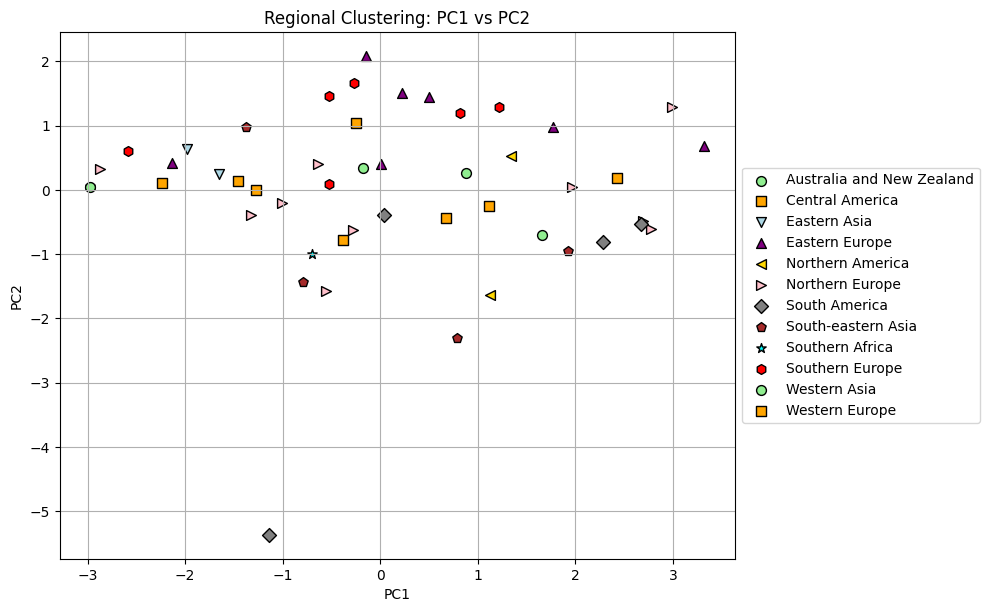

In [35]:
plot_region_clusters(target_df_hpi, 'PC1', 'PC2')

### Plot winner cluster based

In [36]:
def plot_clusters(df, x_col, y_col, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    """
    Plotea un scatter plot 2D coloreando los países según su cluster.
    Los países sin cluster (NaN) se muestran en gris con transparencia.
    """
    plt.figure(figsize=(10, 6))

    # Colores para clusters definidos
    unique_clusters = sorted(df[cluster_col].dropna().unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'brown', 'cyan', 'red', 'olive']
    cluster_color_map = {cluster: colors[i % len(colors)] for i, cluster in enumerate(unique_clusters)}

    # Graficar países con cluster definido
    for cluster in unique_clusters:
        mask = df[cluster_col] == cluster
        highlight_mask = mask & (df[country_col] == highlight_country)
        normal_mask = mask & (df[country_col] != highlight_country)

        # Otros países
        plt.scatter(df.loc[normal_mask, x_col], df.loc[normal_mask, y_col],
                    s=50, c=cluster_color_map[cluster], marker='o',
                    edgecolor='black', label=f'Cluster {int(cluster)}')

        # Paraguay destacado
        if highlight_mask.any():
            plt.scatter(df.loc[highlight_mask, x_col], df.loc[highlight_mask, y_col],
                        s=100, c=cluster_color_map[cluster], marker='X',
                        edgecolor='black', label=f'{highlight_country} (Cluster {int(cluster)})')

    # Graficar países sin cluster
    no_cluster_mask = df[cluster_col].isna()
    if no_cluster_mask.any():
        plt.scatter(df.loc[no_cluster_mask, x_col], df.loc[no_cluster_mask, y_col],
                    s=50, c='gray', alpha=0.5, marker='o',
                    edgecolor='black', label='Sin cluster')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Cluster Mapping: {x_col} vs {y_col}')
    plt.show()

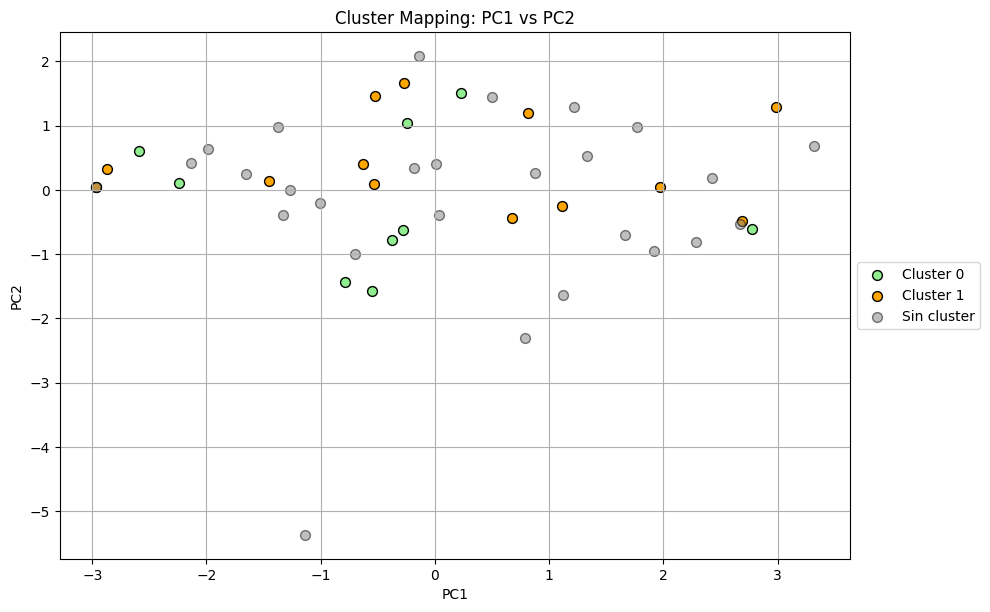

In [37]:
plot_clusters(target_df_hpi, 'PC1', 'PC2')

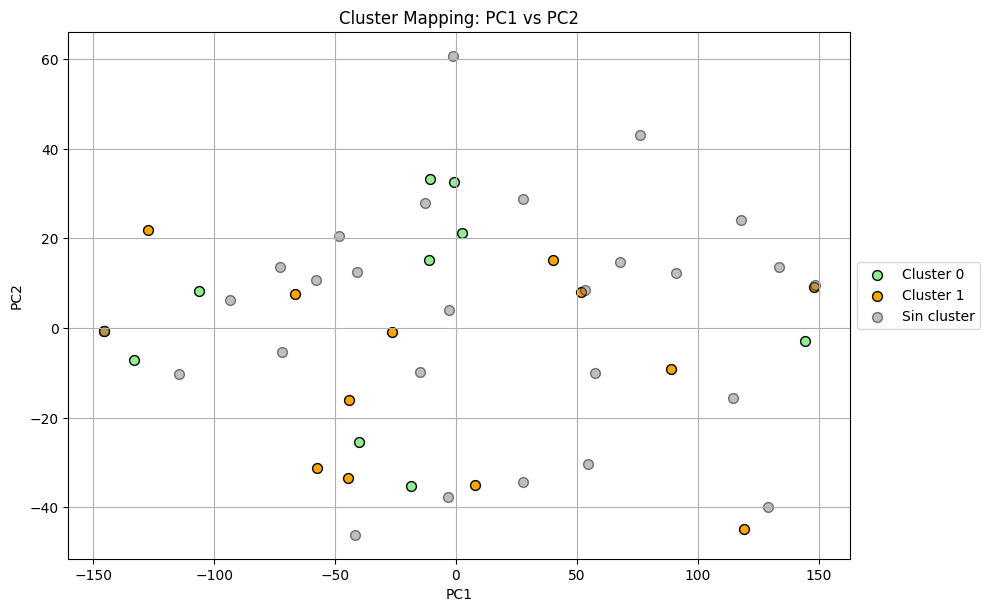

In [38]:
plot_clusters(target_df_hpi, 'PC1', 'PC2')